# Hoja de trabajo 2 — Transformers y mecanismos de atención

**Curso:** CC3092 — Deep Learning y Sistemas Inteligentes  
**Estudiante:** Sebastian Garcia  
**Carné:** 22291  
**Repositorio:** [github.com/SebastianUVG/HT2_Deep_Learning](https://github.com/SebastianUVG/HT2_Deep_Learning.git)

Este notebook implementa y verifica *scaled dot-product attention*, estudia su escalamiento y costo, y analiza las atenciones de **BERT base uncased** y **GPT-2**. Las conclusiones cuantitativas se calculan desde los modelos; no se fijan resultados a mano.

## Uso en Kaggle

1. Importe este `.ipynb` en Kaggle.
2. Active **Internet** para descargar los pesos de Hugging Face.
3. Seleccione un acelerador **GPU** (T4 es suficiente).
4. Ejecute `Run all`. Las figuras y tablas también se guardan en `/kaggle/working/resultados`.

La GPU es recomendable, aunque las secuencias cortas permiten ejecutar el notebook en CPU. Se fuerza la implementación `eager` porque Hugging Face necesita materializar explícitamente las matrices de atención para devolverlas.

In [1]:
# En Kaggle, esta celda asegura una versión compatible de Transformers.
# Si los paquetes ya están disponibles, pip termina rápidamente.
%pip install -q "transformers>=4.45,<5" safetensors

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import json, math, random, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 22291
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("/kaggle/working/resultados") if Path("/kaggle/working").exists() else Path("resultados")
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
print(f"PyTorch: {torch.__version__} | dispositivo: {device} | salida: {OUT.resolve()}")

PyTorch: 2.13.0+cpu | dispositivo: cpu | salida: C:\Users\sebas\OneDrive\Escritorio\Github\Deep learning\HT2_Deep_Learning\resultados


## 1. Atención escalada: implementación y comprobación manual

La operación es

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V.$$

Si las componentes de $q$ y $k$ son independientes, con media 0 y varianza 1, entonces $q\cdot k=\sum_{i=1}^{d_k}q_i k_i$ tiene varianza $d_k$. Dividir por $\sqrt{d_k}$ devuelve la varianza a aproximadamente 1. Sin el escalamiento, al crecer $d_k$ los logits aumentan, la *softmax* se satura y sus gradientes se vuelven pequeños.

El ejemplo siguiente muestra todo el procedimiento: productos punto, escalamiento, *softmax* por fila y combinación ponderada de valores.

In [3]:
def attention_manual(Q, K, V, mask=None):
    # Scaled dot-product attention; devuelve salida, pesos y logits escalados.
    scores = Q @ K.transpose(-2, -1) / math.sqrt(Q.shape[-1])
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ V, weights, scores

# Ejemplo pequeño que puede verificarse a mano.
Q = torch.tensor([[1., 0.], [0., 1.]])
K = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
V = torch.tensor([[1., 0.], [0., 2.], [3., 1.]])
manual_out, manual_w, scaled_scores = attention_manual(Q, K, V)

display(pd.DataFrame(Q @ K.T, columns=["k1", "k2", "k3"], index=["q1", "q2"]).style.set_caption("QKᵀ"))
display(pd.DataFrame(scaled_scores, columns=["k1", "k2", "k3"], index=["q1", "q2"]).style.set_caption("QKᵀ/√dₖ"))
display(pd.DataFrame(manual_w, columns=["k1", "k2", "k3"], index=["q1", "q2"]).style.format("{:.4f}").set_caption("softmax"))
display(pd.DataFrame(manual_out, columns=["salida 1", "salida 2"], index=["q1", "q2"]).style.format("{:.4f}").set_caption("softmax(...)V"))

# F.scaled_dot_product_attention espera batch × cabezas × tokens × dimensión.
torch_out = F.scaled_dot_product_attention(Q[None, None], K[None, None], V[None, None])
max_error = (manual_out - torch_out[0, 0]).abs().max().item()
print(f"Error máximo contra PyTorch: {max_error:.2e}")
assert torch.allclose(manual_out, torch_out[0, 0], atol=1e-6)

,k1,k2,k3
q1,1.000000,0.000000,1.000000
q2,0.000000,1.000000,1.000000


,k1,k2,k3
q1,0.707107,0.000000,0.707107
q2,0.000000,0.707107,0.707107


,k1,k2,k3
q1,0.4011,0.1978,0.4011
q2,0.1978,0.4011,0.4011


,salida 1,salida 2
q1,1.6044,0.7967
q2,1.4011,1.2033


Error máximo contra PyTorch: 0.00e+00


### Parámetros prácticos de PyTorch

- `F.scaled_dot_product_attention`: `attn_mask` restringe pares consulta–llave; `dropout_p` aplica dropout a los pesos; `is_causal=True` impone la máscara triangular; `scale` reemplaza el factor predeterminado $1/\sqrt{d_k}$.
- `nn.MultiheadAttention`: `embed_dim` es el ancho del modelo, `num_heads` lo divide entre cabezas, `batch_first=True` usa `(batch, secuencia, dimensión)` y `kdim`/`vdim` permiten anchos distintos. En `forward`, `key_padding_mask` oculta relleno, `attn_mask` controla pares, `need_weights` solicita pesos y `average_attn_weights=False` conserva cada cabeza.
- `nn.TransformerEncoderLayer`: `d_model`, `nhead`, `dim_feedforward`, `dropout` y `norm_first` configuran ancho, cabezas, MLP, regularización y Pre-LN. `generate_square_subsequent_mask` crea la máscara causal.

## 2. Efecto del escalamiento y costo cuadrático

El primer panel simula logits aleatorios: sin dividir por $\sqrt{d_k}$ la entropía normalizada cae conforme aumenta la dimensión, señal de una distribución saturada. El segundo panel muestra la memoria de **una sola matriz de atención**, por capa, con 12 cabezas y `float32`; no incluye activaciones adicionales ni gradientes.

C:\Users\sebas\AppData\Local\Temp\ipykernel_23260\4071613829.py:21: UserWarning: Glyph 8342 (\N{LATIN SUBSCRIPT SMALL LETTER K}) missing from font(s) Arial.
  fig.tight_layout()
C:\Users\sebas\AppData\Local\Temp\ipykernel_23260\4071613829.py:21: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.tight_layout()
C:\Users\sebas\AppData\Local\Temp\ipykernel_23260\4071613829.py:22: UserWarning: Glyph 8342 (\N{LATIN SUBSCRIPT SMALL LETTER K}) missing from font(s) Arial.
  fig.savefig(OUT / "01_escalamiento_y_costo.png", dpi=180, bbox_inches="tight")
C:\Users\sebas\AppData\Local\Temp\ipykernel_23260\4071613829.py:22: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.savefig(OUT / "01_escalamiento_y_costo.png", dpi=180, bbox_inches="tight")
C:\Users\sebas\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8342 (\N{LATIN SUBSCRIPT SMALL LETTER K}) missing from font(s) Arial.
  fig.canvas.pr

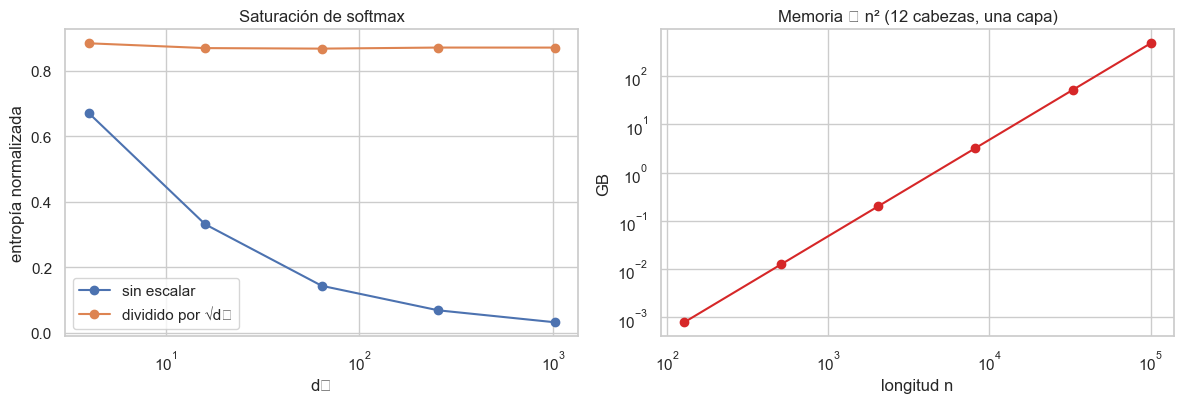

,n,elementos n²,GB por capa
0,128,16384,0.001
1,512,262144,0.013
2,2048,4194304,0.201
3,8192,67108864,3.221
4,32768,1073741824,51.540
5,100000,10000000000,480.000


A 100,000 tokens, solo los pesos de una capa ocupan ≈ 480 GB en float32.


In [4]:
dims = np.array([4, 16, 64, 256, 1024])
entropy_scaled, entropy_unscaled = [], []
for d in dims:
    q = torch.randn(512, d)
    k = torch.randn(512, 32, d)
    logits = torch.einsum("bd,bkd->bk", q, k)
    for target, x in [(entropy_unscaled, logits), (entropy_scaled, logits / math.sqrt(d))]:
        p = x.softmax(-1)
        target.append((-(p * p.clamp_min(1e-12).log()).sum(-1) / math.log(p.shape[-1])).mean().item())

lengths = np.array([128, 512, 2048, 8192, 32768, 100000])
memory_gb = 12 * lengths.astype(np.float64) ** 2 * 4 / 1e9

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(dims, entropy_unscaled, "o-", label="sin escalar")
axes[0].plot(dims, entropy_scaled, "o-", label="dividido por √dₖ")
axes[0].set(xscale="log", xlabel="dₖ", ylabel="entropía normalizada", title="Saturación de softmax")
axes[0].legend()
axes[1].plot(lengths, memory_gb, "o-", color="tab:red")
axes[1].set(xscale="log", yscale="log", xlabel="longitud n", ylabel="GB", title="Memoria ∝ n² (12 cabezas, una capa)")
fig.tight_layout()
fig.savefig(OUT / "01_escalamiento_y_costo.png", dpi=180, bbox_inches="tight")
plt.show()

cost_table = pd.DataFrame({"n": lengths, "elementos n²": lengths.astype(object) ** 2, "GB por capa": memory_gb})
display(cost_table.style.format({"GB por capa": "{:.3f}"}))
print(f"A 100,000 tokens, solo los pesos de una capa ocupan ≈ {memory_gb[-1]:.0f} GB en float32.")

**Alternativas para secuencias largas.** FlashAttention calcula atención exacta por bloques y evita materializar toda la matriz en memoria HBM: reduce tráfico y memoria, pero el número de productos sigue siendo cuadrático. La atención por ventanas reduce tiempo y memoria a $O(nw)$, sacrificando conexiones globales directas (salvo tokens globales o capas sucesivas). La atención lineal reordena o aproxima el kernel para acercarse a $O(n)$, a cambio de cambiar la atención exacta y, potencialmente, la calidad/estabilidad.

## 3. Carga de BERT y GPT-2

BERT usa atención bidireccional y tokens especiales `[CLS]`/`[SEP]`. GPT-2 es autorregresivo: cada consulta solo puede atender su prefijo. `output_attentions=True` devuelve una tupla por capa, cada tensor con forma `batch × cabezas × n × n`.

In [5]:
MODEL_KW = dict(output_attentions=True, attn_implementation="eager")
tok_bert = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased", **MODEL_KW).to(device).eval()
tok_gpt2 = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModel.from_pretrained("gpt2", **MODEL_KW).to(device).eval()

print(f"BERT: {bert.config.num_hidden_layers} capas, {bert.config.num_attention_heads} cabezas")
print(f"GPT-2: {gpt2.config.n_layer} capas, {gpt2.config.n_head} cabezas")

BERT: 12 capas, 12 cabezas
GPT-2: 12 capas, 12 cabezas


In [6]:
def run_model(text, tokenizer, model):
    encoded = tokenizer(text, return_tensors="pt")
    encoded = {k: v.to(device) for k, v in encoded.items()}
    with torch.inference_mode():
        output = model(**encoded, output_attentions=True)
    tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])
    attentions = torch.stack([a[0].float().cpu() for a in output.attentions])
    # forma: capas × cabezas × consultas × llaves
    return tokens, attentions

def plot_heads(tokens, attentions, selections, title, filename):
    fig, axes = plt.subplots(2, 2, figsize=(15, 12), constrained_layout=True)
    for ax, (layer, head) in zip(axes.flat, selections):
        sns.heatmap(attentions[layer, head].numpy(), cmap="mako", vmin=0, vmax=1,
                    xticklabels=tokens, yticklabels=tokens, ax=ax, cbar_kws={"shrink": .7})
        ax.set(title=f"{title} — capa {layer + 1}, cabeza {head + 1}", xlabel="llave", ylabel="consulta")
        ax.tick_params(axis="x", rotation=60)
        ax.tick_params(axis="y", rotation=0)
    fig.savefig(OUT / filename, dpi=180, bbox_inches="tight")
    plt.show()

sentence = "The curious student carefully solved the difficult problem, and then celebrated."
bert_tokens, bert_attn = run_model(sentence, tok_bert, bert)
gpt_tokens, gpt_attn = run_model(sentence, tok_gpt2, gpt2)
print("Tokens BERT:", bert_tokens)
print("Tokens GPT-2:", gpt_tokens)
print("BERT:", tuple(bert_attn.shape), "| GPT-2:", tuple(gpt_attn.shape))

Tokens BERT: ['[CLS]', 'the', 'curious', 'student', 'carefully', 'solved', 'the', 'difficult', 'problem', ',', 'and', 'then', 'celebrated', '.', '[SEP]']
Tokens GPT-2: ['The', 'Ġcurious', 'Ġstudent', 'Ġcarefully', 'Ġsolved', 'Ġthe', 'Ġdifficult', 'Ġproblem', ',', 'Ġand', 'Ġthen', 'Ġcelebrated', '.']
BERT: (12, 12, 15, 15) | GPT-2: (12, 12, 13, 13)


## 4. Mapas de calor: cuatro cabezas de capas distintas

Cada fila representa el token que consulta y cada columna el token atendido. Se eligen capas tempranas, medias y profundas para no seleccionar ejemplos únicamente por su apariencia.

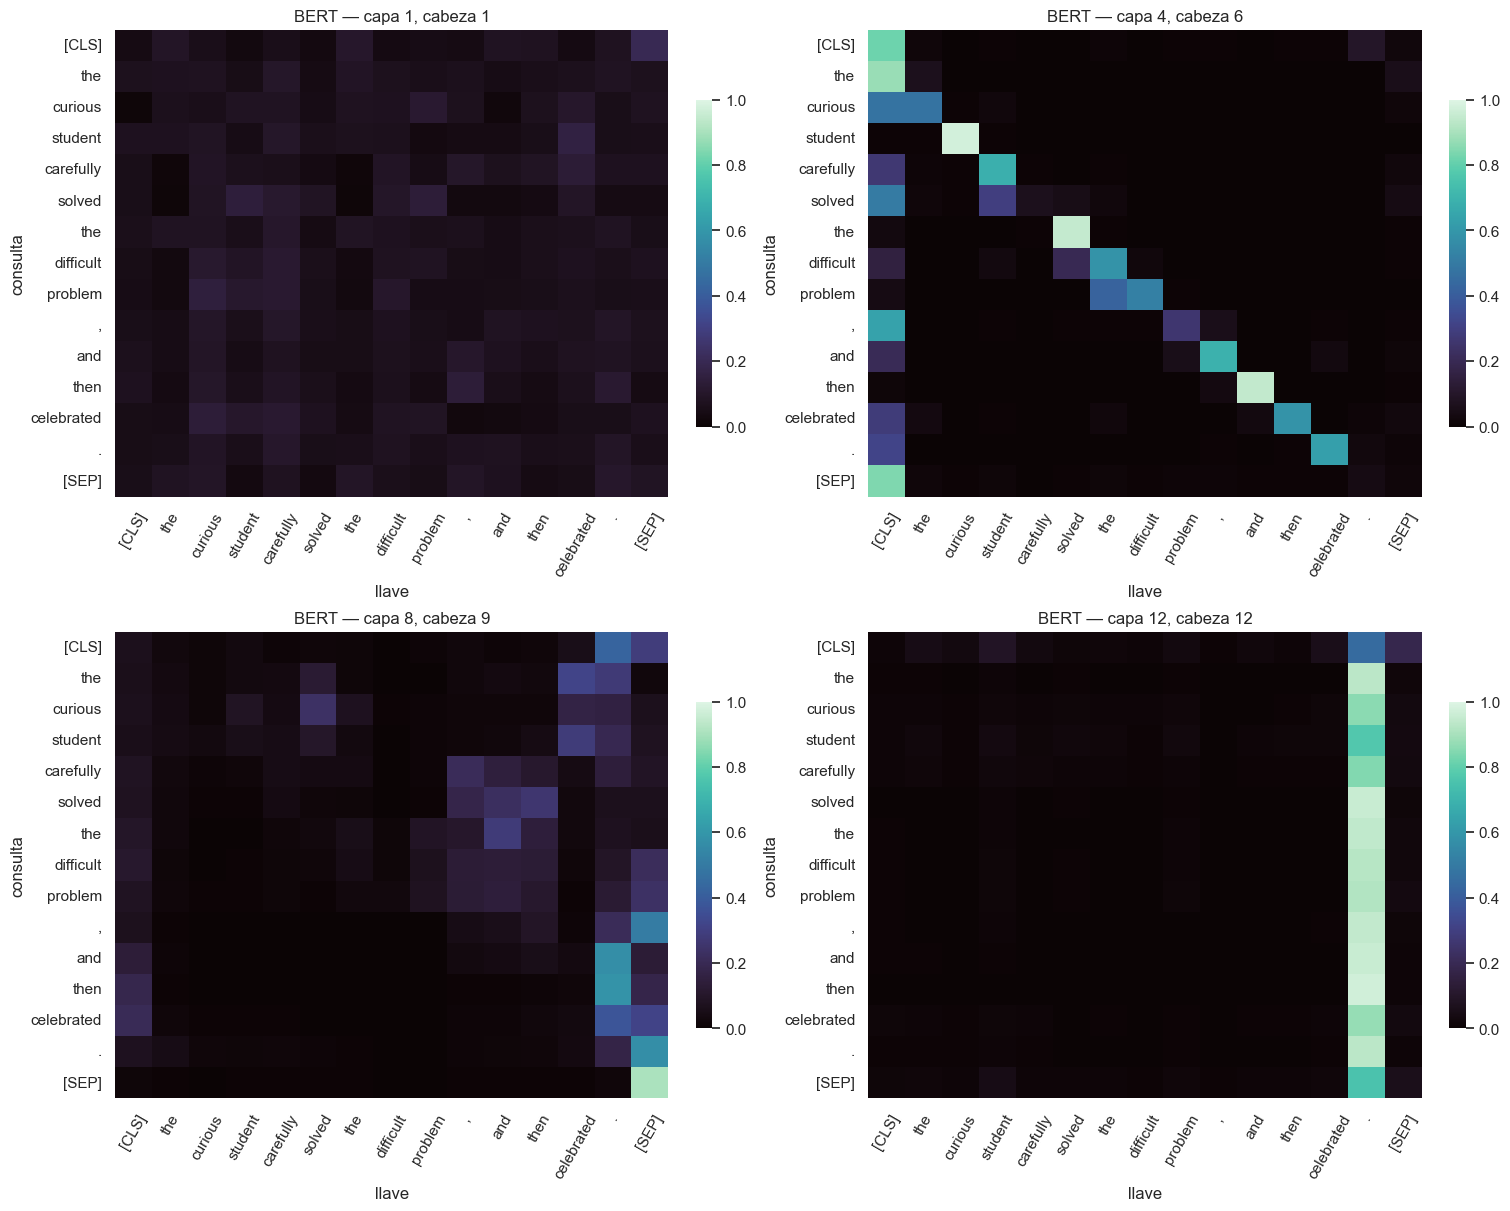

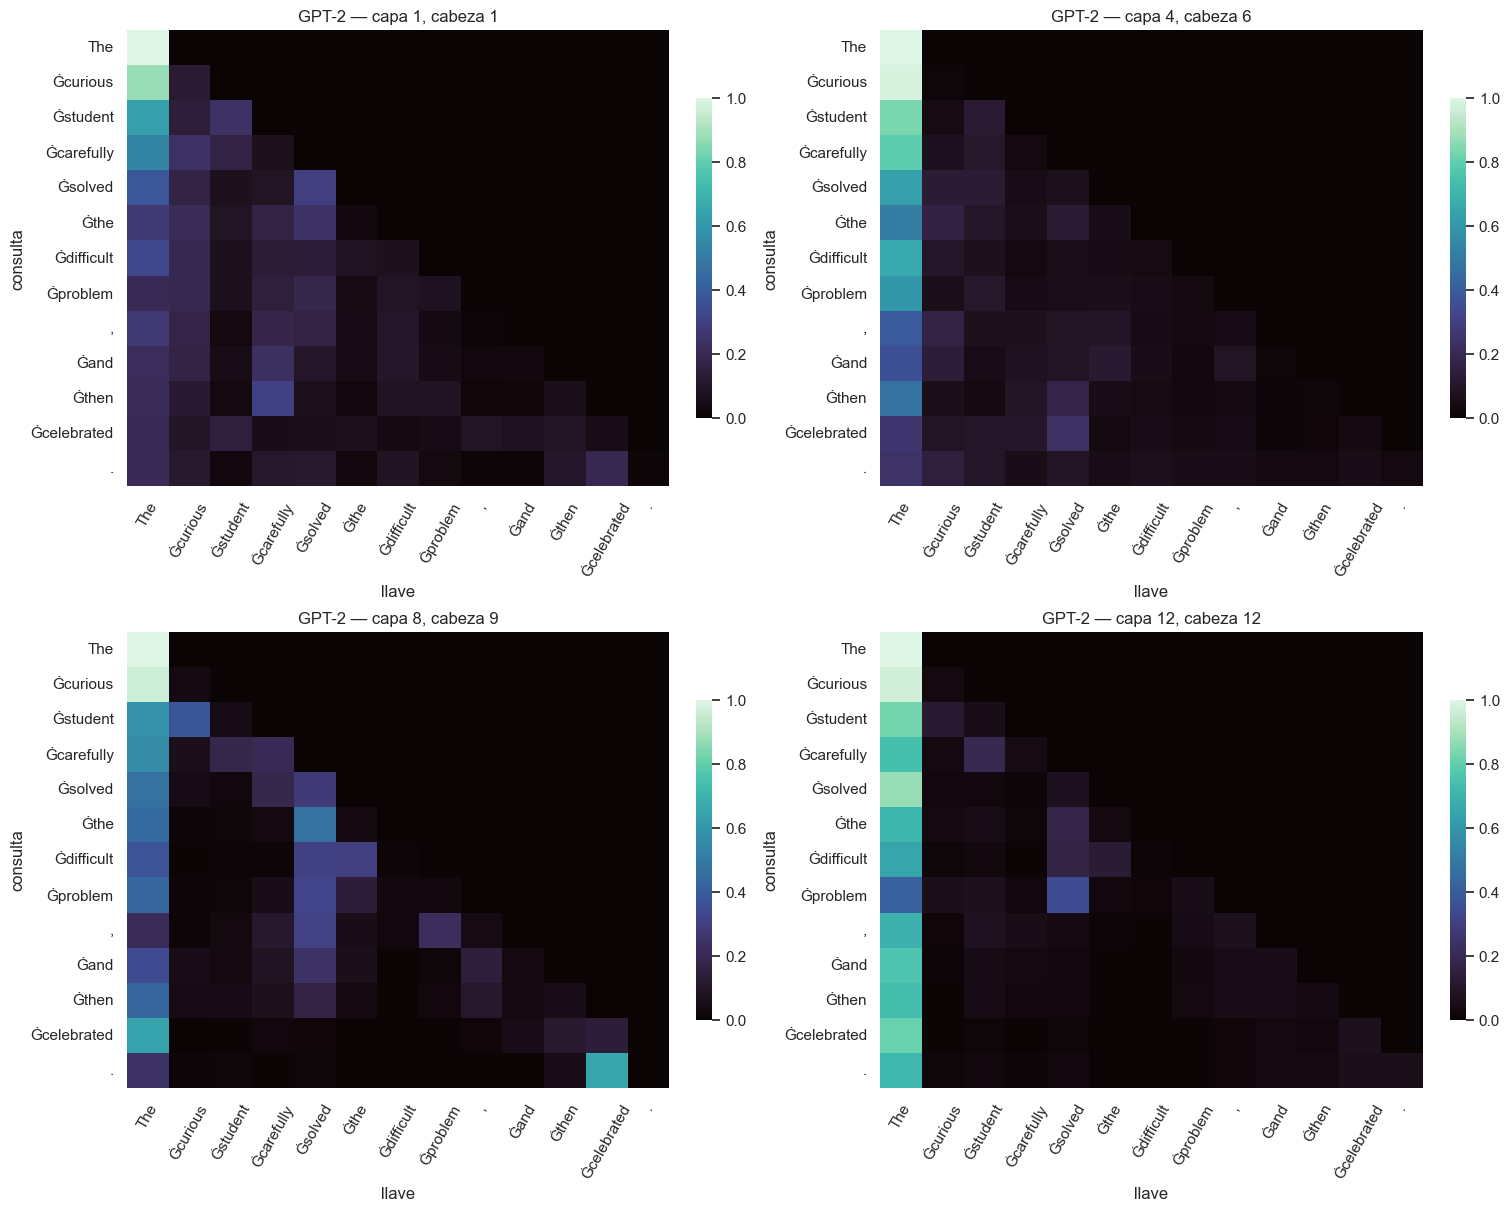

In [7]:
selections = [(0, 0), (3, 5), (7, 8), (11, 11)]
plot_heads(bert_tokens, bert_attn, selections, "BERT", "02_mapas_bert.png")
plot_heads(gpt_tokens, gpt_attn, selections, "GPT-2", "03_mapas_gpt2.png")

## 5. Contraste pronominal en BERT

Se recorren las 144 cabezas, sin escoger una manualmente. Para cada cabeza se mide:

$$m=(A_{it	o animal}-A_{it	o street})_{tired}+(A_{it	o street}-A_{it	o animal})_{wide}.$$

Una cabeza cumple estrictamente el patrón solicitado si ambos términos son positivos. Se reporta la mejor por el mínimo de ambos márgenes; si ninguna cumple, el notebook lo dice explícitamente en vez de forzar la conclusión.

,capa,cabeza,tired→animal,tired→street,wide→animal,wide→street,margen_tired,margen_wide,cumple_ambos,criterio
0,7,11,0.2843,0.0671,0.0119,0.5902,0.2172,0.5782,True,0.2172
1,9,5,0.2417,0.0145,0.0462,0.2091,0.2272,0.1629,True,0.1629
2,9,8,0.2052,0.0503,0.0611,0.1944,0.1550,0.1333,True,0.1333
3,5,11,0.3330,0.0952,0.1674,0.2883,0.2378,0.1208,True,0.1208
4,7,5,0.2386,0.1339,0.0815,0.2510,0.1047,0.1695,True,0.1047
5,9,4,0.0822,0.0256,0.0130,0.1594,0.0566,0.1465,True,0.0566
6,9,2,0.1150,0.0043,0.0154,0.0564,0.1107,0.0409,True,0.0409
7,12,9,0.0449,0.0074,0.0174,0.0760,0.0374,0.0586,True,0.0374
8,12,10,0.0661,0.0233,0.0183,0.0457,0.0429,0.0274,True,0.0274
9,10,9,0.4544,0.0025,0.0229,0.0449,0.4519,0.0221,True,0.0221


Mejor cabeza: capa 7, cabeza 11 | cumple ambos: True


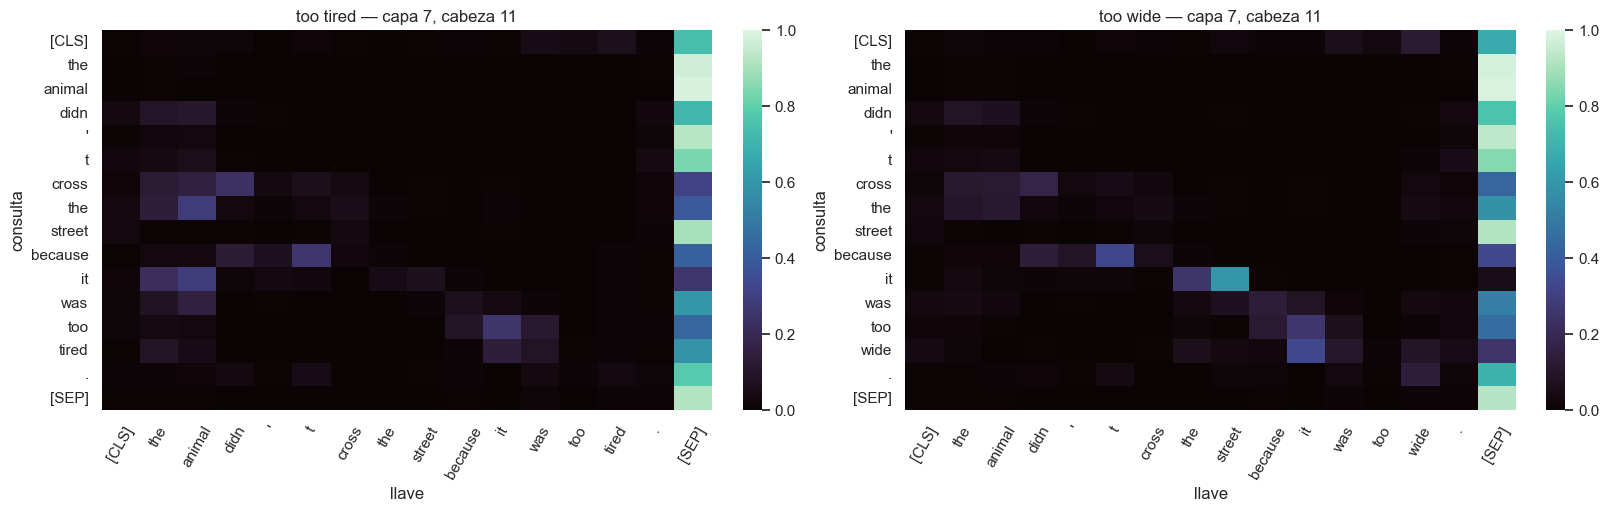

In [8]:
s_tired = "The animal didn't cross the street because it was too tired."
s_wide = "The animal didn't cross the street because it was too wide."
toks_t, attn_t = run_model(s_tired, tok_bert, bert)
toks_w, attn_w = run_model(s_wide, tok_bert, bert)
assert toks_t[:-3] == toks_w[:-3], "La tokenización común cambió inesperadamente."

def token_index(tokens, token):
    matches = [i for i, t in enumerate(tokens) if t == token]
    if len(matches) != 1:
        raise ValueError(f"Se esperaba una aparición de {token!r}; se encontraron {matches}: {tokens}")
    return matches[0]

i_animal, i_street, i_it = (token_index(toks_t, x) for x in ["animal", "street", "it"])
rows = []
for layer in range(attn_t.shape[0]):
    for head in range(attn_t.shape[1]):
        tired_animal = attn_t[layer, head, i_it, i_animal].item()
        tired_street = attn_t[layer, head, i_it, i_street].item()
        wide_animal = attn_w[layer, head, i_it, i_animal].item()
        wide_street = attn_w[layer, head, i_it, i_street].item()
        margin_tired = tired_animal - tired_street
        margin_wide = wide_street - wide_animal
        rows.append({"capa": layer + 1, "cabeza": head + 1,
                     "tired→animal": tired_animal, "tired→street": tired_street,
                     "wide→animal": wide_animal, "wide→street": wide_street,
                     "margen_tired": margin_tired, "margen_wide": margin_wide,
                     "cumple_ambos": margin_tired > 0 and margin_wide > 0,
                     "criterio": min(margin_tired, margin_wide)})

coref = pd.DataFrame(rows).sort_values(["cumple_ambos", "criterio"], ascending=False).reset_index(drop=True)
best = coref.iloc[0]
display(coref.head(10).style.format({c: "{:.4f}" for c in coref.columns if "→" in c or "margen" in c or c == "criterio"}))
print(f"Mejor cabeza: capa {int(best.capa)}, cabeza {int(best.cabeza)} | cumple ambos: {bool(best.cumple_ambos)}")

layer, head = int(best.capa) - 1, int(best.cabeza) - 1
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
for ax, tokens, attn, label in [(axes[0], toks_t, attn_t, "too tired"), (axes[1], toks_w, attn_w, "too wide")]:
    sns.heatmap(attn[layer, head].numpy(), cmap="mako", vmin=0, vmax=1,
                xticklabels=tokens, yticklabels=tokens, ax=ax)
    ax.set(title=f"{label} — capa {layer+1}, cabeza {head+1}", xlabel="llave", ylabel="consulta")
    ax.tick_params(axis="x", rotation=60)
    ax.tick_params(axis="y", rotation=0)
fig.savefig(OUT / "04_contraste_pronominal.png", dpi=180, bbox_inches="tight")
plt.show()
coref.to_csv(OUT / "contraste_pronominal.csv", index=False)

## 6. Causalidad y *attention sinks* en GPT-2

La máscara causal debe anular exactamente toda entrada sobre la diagonal. Después se calcula, por capa, la fracción media enviada al primer token, promediando cabezas y posiciones de consulta. Un valor persistentemente alto es evidencia descriptiva compatible con un *attention sink*: el primer token recibe masa aun cuando no aporta semántica evidente. No demuestra por sí solo causalidad ni utilidad.

,capa,atención media al primer token
0,1,0.1901
1,2,0.3199
2,3,0.3407
3,4,0.4994
4,5,0.5084
5,6,0.7350
6,7,0.7005
7,8,0.7725
8,9,0.6862
9,10,0.7724


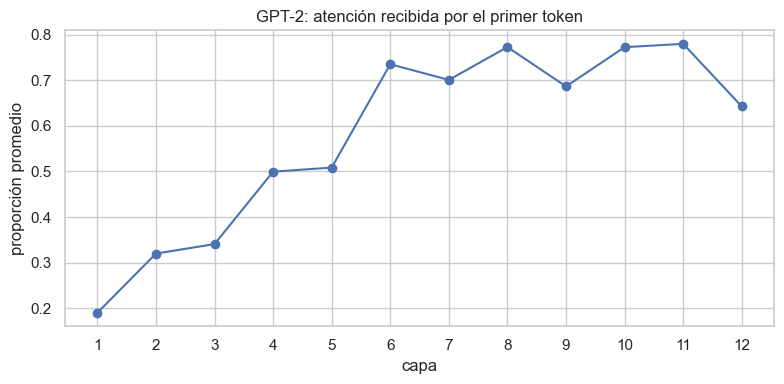

Máximo sobre la diagonal: 0.00e+00 (matriz triangular inferior verificada).


In [9]:
sink_text = ("In a quiet laboratory, researchers compared several neural architectures and carefully "
             "recorded how every layer distributed attention across the complete sequence of tokens.")
sink_tokens, sink_attn = run_model(sink_text, tok_gpt2, gpt2)
upper_max = torch.triu(sink_attn, diagonal=1).abs().max().item()
assert upper_max < 1e-7, f"Hay atención hacia el futuro: {upper_max}"

first_token_share = sink_attn[..., 0].mean(dim=(1, 2)).numpy()
sink_df = pd.DataFrame({"capa": np.arange(1, len(first_token_share) + 1),
                        "atención media al primer token": first_token_share})
display(sink_df.style.format({"atención media al primer token": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sink_df["capa"], sink_df["atención media al primer token"], "o-")
ax.set(xlabel="capa", ylabel="proporción promedio", title="GPT-2: atención recibida por el primer token", xticks=sink_df["capa"])
fig.tight_layout(); fig.savefig(OUT / "05_attention_sink.png", dpi=180, bbox_inches="tight"); plt.show()
print(f"Máximo sobre la diagonal: {upper_max:.2e} (matriz triangular inferior verificada).")
sink_df.to_csv(OUT / "attention_sink_por_capa.csv", index=False)

## 7. Entropía promedio por capa

Se usa entropía normalizada para comparar distribuciones con diferente número de llaves disponibles. En BERT se divide por $\log n$. En GPT-2 la consulta $i$ solo tiene $i+1$ llaves, así que se divide por $\log(i+1)$ y se omite la primera consulta, cuya entropía es necesariamente cero. Valores cercanos a 1 son difusos; cercanos a 0, concentrados.

,capa,BERT,GPT-2
0,1,0.7825,0.6585
1,2,0.6276,0.7448
2,3,0.5466,0.6510
3,4,0.6080,0.5050
4,5,0.5403,0.4398
5,6,0.4284,0.3777
6,7,0.4218,0.4508
7,8,0.3994,0.3323
8,9,0.5027,0.4546
9,10,0.5795,0.3117


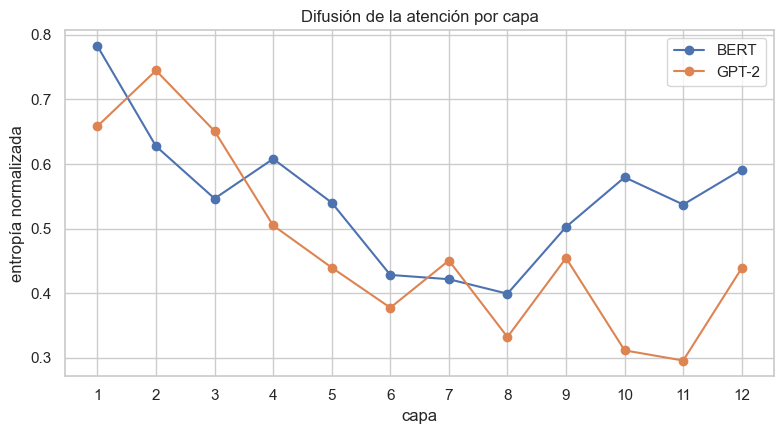

In [10]:
def entropy_by_layer(attn, causal=False):
    p = attn.clamp_min(1e-12)
    h = -(p * p.log()).sum(-1)  # capas × cabezas × consultas
    n = p.shape[-1]
    if causal:
        denom = torch.arange(1, n + 1, dtype=h.dtype).log()
        normalized = h[..., 1:] / denom[1:]
    else:
        normalized = h / math.log(n)
    return normalized.mean(dim=(1, 2)).numpy()

analysis_text = "When the old bridge shook during the storm, the careful engineer inspected every support before reopening it."
btok_e, battn_e = run_model(analysis_text, tok_bert, bert)
gtok_e, gattn_e = run_model(analysis_text, tok_gpt2, gpt2)
bert_entropy = entropy_by_layer(battn_e, causal=False)
gpt_entropy = entropy_by_layer(gattn_e, causal=True)
entropy_df = pd.DataFrame({"capa": np.arange(1, 13), "BERT": bert_entropy, "GPT-2": gpt_entropy})
display(entropy_df.style.format({"BERT": "{:.4f}", "GPT-2": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(entropy_df.capa, entropy_df.BERT, "o-", label="BERT")
ax.plot(entropy_df.capa, entropy_df["GPT-2"], "o-", label="GPT-2")
ax.set(xlabel="capa", ylabel="entropía normalizada", title="Difusión de la atención por capa", xticks=entropy_df.capa)
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "06_entropia_por_capa.png", dpi=180, bbox_inches="tight"); plt.show()
entropy_df.to_csv(OUT / "entropia_por_capa.csv", index=False)

## 8. Evidencia de especialización de cabezas

Para hacer el análisis reproducible, se resumen cinco patrones simples: atención a la misma posición, token anterior, token siguiente, puntuación y tokens especiales. El valor de cada cabeza es la masa promedio que deposita en el patrón. Una puntuación alta identifica un comportamiento, pero no prueba que esa cabeza sea indispensable: varias cabezas pueden ser redundantes y la ablación sería una prueba más fuerte.

In [11]:
def head_pattern_table(tokens, attn, special_tokens=()):
    L, H, n, _ = attn.shape
    punct = {i for i, t in enumerate(tokens) if t.strip("Ġ▁") in {".", ",", ";", ":", "!", "?"}}
    special = {i for i, t in enumerate(tokens) if t in set(special_tokens)}
    rows = []
    for l in range(L):
        for h in range(H):
            a = attn[l, h]
            row = {"capa": l + 1, "cabeza": h + 1,
                   "misma": a.diag().mean().item(),
                   "anterior": a[torch.arange(1, n), torch.arange(n - 1)].mean().item(),
                   "siguiente": a[torch.arange(n - 1), torch.arange(1, n)].mean().item(),
                   "puntuación": a[:, sorted(punct)].sum(-1).mean().item() if punct else 0.0,
                   "especial": a[:, sorted(special)].sum(-1).mean().item() if special else 0.0}
            rows.append(row)
    return pd.DataFrame(rows)

bert_patterns = head_pattern_table(bert_tokens, bert_attn, ("[CLS]", "[SEP]"))
gpt_patterns = head_pattern_table(gpt_tokens, gpt_attn)

best_patterns = []
for model_name, table in [("BERT", bert_patterns), ("GPT-2", gpt_patterns)]:
    for pattern in ["misma", "anterior", "siguiente", "puntuación", "especial"]:
        if model_name == "GPT-2" and pattern == "especial":
            continue
        r = table.loc[table[pattern].idxmax()]
        best_patterns.append({"modelo": model_name, "patrón": pattern,
                              "capa": int(r.capa), "cabeza": int(r.cabeza), "masa promedio": r[pattern]})
best_patterns_df = pd.DataFrame(best_patterns)
display(best_patterns_df.style.format({"masa promedio": "{:.4f}"}))
best_patterns_df.to_csv(OUT / "especializacion_cabezas.csv", index=False)

,modelo,patrón,capa,cabeza,masa promedio
0,BERT,misma,12,9,0.4294
1,BERT,anterior,7,12,0.6347
2,BERT,siguiente,3,10,0.9291
3,BERT,puntuación,12,12,0.8701
4,BERT,especial,2,7,0.9172
5,GPT-2,misma,1,2,0.9683
6,GPT-2,anterior,5,12,0.9979
7,GPT-2,siguiente,1,1,0.0000
8,GPT-2,puntuación,3,6,0.1715


## 9. Resumen automático de resultados

Esta celda traduce las métricas obtenidas a afirmaciones concretas. Las visualizaciones son útiles para formular hipótesis sobre patrones, pero los pesos no son una explicación causal completa: pueden diferir de otras medidas de importancia y distribuciones distintas pueden producir resultados semejantes.

In [12]:
def trend_description(values):
    x = np.arange(len(values))
    slope = np.polyfit(x, values, 1)[0]
    if abs(slope) < 0.002:
        return "sin una tendencia lineal fuerte"
    return "más difusa" if slope > 0 else "más concentrada"

summary = {
    "dispositivo": str(device),
    "error_verificacion_attention": max_error,
    "maximo_encima_diagonal_gpt2": upper_max,
    "mejor_cabeza_coreferencia": {"capa": int(best.capa), "cabeza": int(best.cabeza),
                                   "cumple_ambos": bool(best.cumple_ambos),
                                   "margen_tired": float(best.margen_tired), "margen_wide": float(best.margen_wide)},
    "tendencia_entropia_bert": trend_description(bert_entropy),
    "tendencia_entropia_gpt2": trend_description(gpt_entropy),
    "capa_mayor_sink_gpt2": int(np.argmax(first_token_share) + 1),
    "mayor_sink_gpt2": float(np.max(first_token_share)),
}

display(Markdown(f'''
### Hallazgos

- La implementación manual coincide con PyTorch con error máximo **{max_error:.2e}**.
- GPT-2 es causal: el mayor peso sobre la diagonal es **{upper_max:.2e}**.
- Para el contraste pronominal, la mejor candidata es la **capa {int(best.capa)}, cabeza {int(best.cabeza)}**; **{'sí' if best.cumple_ambos else 'no'}** satisface simultáneamente ambos cambios de antecedente.
- La atención se vuelve **{trend_description(bert_entropy)}** con la profundidad en BERT y **{trend_description(gpt_entropy)}** en GPT-2 según la pendiente de la entropía normalizada.
- La mayor atención promedio al primer token de GPT-2 aparece en la **capa {np.argmax(first_token_share)+1}** ({np.max(first_token_share):.4f}).
- Las mejores cabezas por patrón difieren entre sí (tabla anterior), evidencia descriptiva de especialización. Esto no implica que todas sean necesarias ni que los pesos expliquen causalmente la predicción.
'''))

with open(OUT / "resumen.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(f"Resultados guardados en: {OUT.resolve()}")


### Hallazgos

- La implementación manual coincide con PyTorch con error máximo **0.00e+00**.
- GPT-2 es causal: el mayor peso sobre la diagonal es **0.00e+00**.
- Para el contraste pronominal, la mejor candidata es la **capa 7, cabeza 11**; **sí** satisface simultáneamente ambos cambios de antecedente.
- La atención se vuelve **más concentrada** con la profundidad en BERT y **más concentrada** en GPT-2 según la pendiente de la entropía normalizada.
- La mayor atención promedio al primer token de GPT-2 aparece en la **capa 11** (0.7796).
- Las mejores cabezas por patrón difieren entre sí (tabla anterior), evidencia descriptiva de especialización. Esto no implica que todas sean necesarias ni que los pesos expliquen causalmente la predicción.


Resultados guardados en: C:\Users\sebas\OneDrive\Escritorio\Github\Deep learning\HT2_Deep_Learning\resultados


## 10. Discusión breve

- **Por qué escala mejor que una RNN.** En entrenamiento, todos los tokens de una capa pueden procesarse en paralelo y el camino entre dos posiciones es de una operación de atención, frente a muchos pasos recurrentes. La contrapartida es el costo temporal y de memoria cuadrático en $n$.
- **Cabezas especializadas.** Los máximos de atención a posición propia, vecinos, puntuación y tokens especiales aparecen en cabezas distintas. Aun así, algunas cabezas pueden ser redundantes; demostrar utilidad requiere ablaciones o intervención causal.
- **Atención no equivale a explicación.** Los mapas describen el flujo de mezcla dentro del modelo, pero no bastan para atribuir una decisión. Jain y Wallace muestran desacuerdos con gradientes y distribuciones alternativas; Wiegreffe y Pinter señalan que la validez depende de la definición de explicación y proponen controles más rigurosos.
- **Cuándo usar RNN/CNN.** Una RNN puede convenir para inferencia estrictamente *streaming* con estado compacto y recursos mínimos; una CNN para patrones locales, paralelismo y costo lineal con longitud.
- **Documentos de 100,000 tokens.** La atención estándar es inviable por $n^2$: con 12 cabezas, una sola matriz por capa ronda 480 GB en `float32`. Consideraría ventanas dispersas con algunos tokens globales, modelos jerárquicos o atención lineal; FlashAttention ayuda a la memoria práctica, pero por sí sola no elimina el cómputo cuadrático.

## Referencias

1. Bahdanau, D., Cho, K. y Bengio, Y. (2015). *Neural Machine Translation by Jointly Learning to Align and Translate*. ICLR. https://arxiv.org/abs/1409.0473
2. Luong, M.-T., Pham, H. y Manning, C. D. (2015). *Effective Approaches to Attention-based Neural Machine Translation*. EMNLP. https://arxiv.org/abs/1508.04025
3. Vaswani, A. et al. (2017). *Attention Is All You Need*. NeurIPS. https://arxiv.org/abs/1706.03762
4. Jain, S. y Wallace, B. C. (2019). *Attention is not Explanation*. NAACL. https://arxiv.org/abs/1902.10186
5. Wiegreffe, S. y Pinter, Y. (2019). *Attention is not not Explanation*. EMNLP. https://arxiv.org/abs/1908.04626
6. Xiao, G. et al. (2023). *Efficient Streaming Language Models with Attention Sinks*. ICLR 2024. https://arxiv.org/abs/2309.17453
7. Dao, T. et al. (2022). *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness*. NeurIPS. https://arxiv.org/abs/2205.14135
8. PyTorch. *Scaled dot product attention*. https://pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html
9. Hugging Face. *Model outputs*. https://huggingface.co/docs/transformers/main_classes/output